# Tyre degradation, relative-pace analysis

This notebook recreates the diagnosis, fits the race fixed-effects model, and compares it with a zero-degradation baseline. Each target is a lap time minus the median of the first three clean laps in that driver's stint. The raw lap time is used; race-lap fixed effects account for common fuel burn and track evolution. Missing model fields are counted before rows are excluded. No database schema is changed.

Run the cells from top to bottom. The analysis cell can take several minutes because it fits one model per race and performs leave-one-race-out validation.

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from f1engine.tyre_model_v2 import run_analysis

results = run_analysis()
print(f"Input clean-view rows: {len(results['raw_laps']):,}")
print(f"Rows used after explicit exclusions: {len(results['data']):,}")
print(f"New model artifact: {results['artifact_path']}")
display(pd.Series(results["exclusions"], name="count").to_frame())

Race 2022-1 has a rank-deficient fixed-effects design (130/131); retaining finite slope estimates and flagging the fit.
Race 2022-10 has a rank-deficient fixed-effects design (94/95); retaining finite slope estimates and flagging the fit.
Race 2022-11 has a rank-deficient fixed-effects design (112/113); retaining finite slope estimates and flagging the fit.
Race 2022-12 has a rank-deficient fixed-effects design (93/94); retaining finite slope estimates and flagging the fit.
c:\Users\Taksh Doshi\OneDrive\Desktop\f1-telemetry-engine\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))
Race 2022-13 has a rank-deficient fixed-effects design (129/130); retaining finite slope estimates and flagging the fit.
Race 2022-14 has a rank-deficient fixed-effects design (95/96); retaining finite slope estimates and flagging the fit.
Race 2022-15 has a rank-deficient fixed-effects design (146

Input clean-view rows: 60,706
Rows used after explicit exclusions: 60,227
New model artifact: C:\Users\Taksh Doshi\OneDrive\Desktop\f1-telemetry-engine\models\tyre_degradation_relative.joblib


,count
input_rows,60706
missing_values_by_field_total,748
invalid_numeric_by_field,0
rows_excluded_for_required_fields,479
missing_year,0
missing_round,0
missing_circuit,0
missing_driver_code,0
missing_compound,330
missing_tyre_life,418


## Diagnosis: tyre age and race progress

A high correlation between tyre age and stint lap means the data has little independent variation for separating wear from stint progression. The fuel-sensitivity chart repeats the old driver-adjusted slope fit under four explicitly stated fuel-burn assumptions.

,tyre_set,laps,tyre_life_vs_race_lap_r,tyre_life_vs_stint_lap_r,fresh_flag_unknown_laps
0,all,60227,0.524926,0.977309,0
1,fresh,47247,0.538471,0.985876,0
2,used,12980,0.471794,0.967376,0


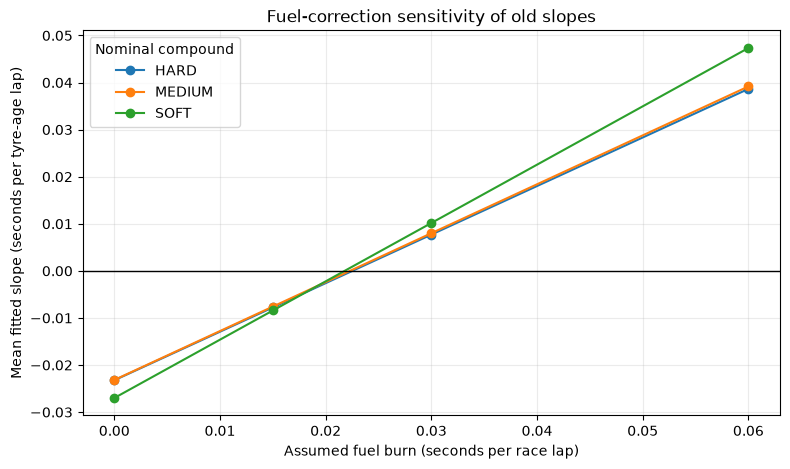

In [2]:
display(results["correlations"])

fuel_summary = results["fuel_summary"]
fig, ax = plt.subplots(figsize=(9, 5))
for compound, group in fuel_summary.groupby("compound", sort=True):
    group = group.sort_values("fuel_burn_seconds_per_lap")
    ax.plot(
        group["fuel_burn_seconds_per_lap"],
        group["mean_slope_seconds_per_lap"],
        marker="o",
        label=compound,
    )
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Fuel-correction sensitivity of old slopes", xlabel="Assumed fuel burn (seconds per race lap)", ylabel="Mean fitted slope (seconds per tyre-age lap)")
ax.legend(title="Nominal compound")
ax.grid(alpha=0.25)
plt.show()

## Example stints

Each line uses the stint's first-three-clean-lap median as its reference. Short stints use the available laps and are reported in the analysis rather than silently removed.

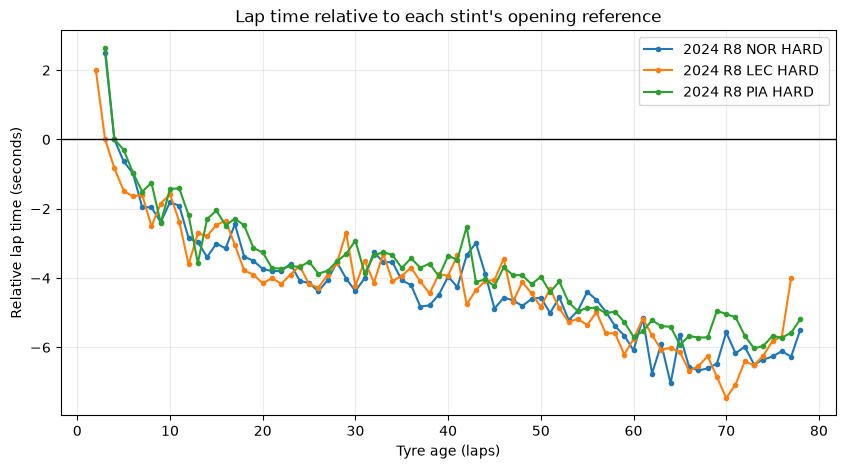

In [3]:
model_data = results["data"]
stint_sizes = model_data.groupby("driver_stint_id").size().sort_values(ascending=False)
example_ids = stint_sizes.head(3).index
fig, ax = plt.subplots(figsize=(10, 5))
for stint_id in example_ids:
    stint = model_data.loc[model_data["driver_stint_id"].eq(stint_id)].sort_values("tyre_life")
    first = stint.iloc[0]
    label = f"{first['year']} R{first['round']} {first['driver_code']} {first['compound']}"
    ax.plot(stint["tyre_life"], stint["relative_time_seconds"], marker=".", label=label)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Lap time relative to each stint's opening reference", xlabel="Tyre age (laps)", ylabel="Relative lap time (seconds)")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## Pooled degradation slopes and uncertainty

Bars show the pooled estimate and 95% interval. Negative estimates are left visible; they are evidence that these data and controls do not yet identify a physically credible wear effect.

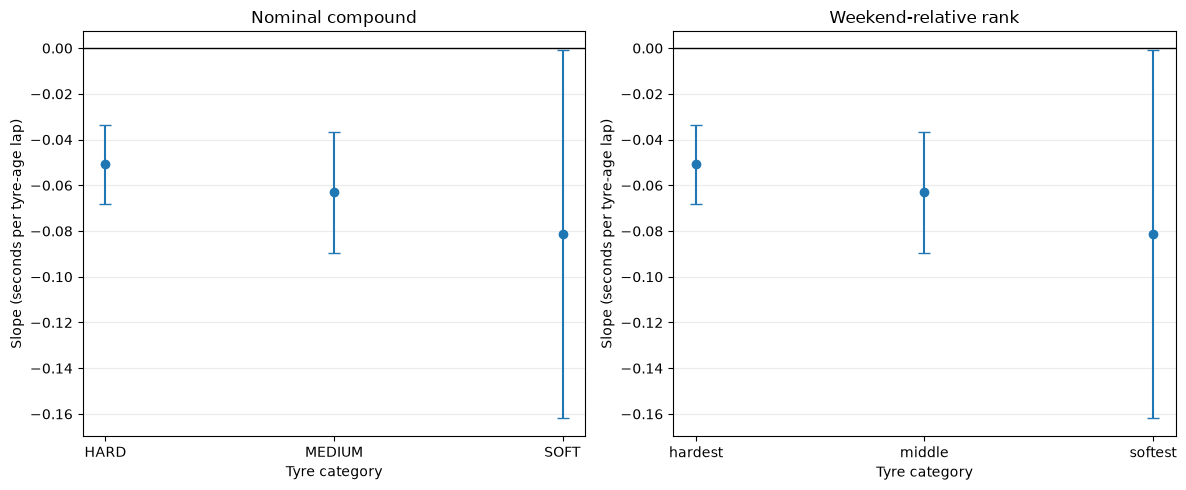

,pooled_slope_seconds_per_lap,standard_error,lower_95,upper_95,race_estimates,tau_squared,negative_slope_share,compound
0,-0.050874,0.008638,-0.068171,-0.033577,58,0.004108,0.706897,HARD
1,-0.063053,0.013180,-0.089391,-0.036714,64,0.010675,0.656250,MEDIUM
2,-0.081256,0.039112,-0.161808,-0.000703,26,0.038661,0.500000,SOFT


,pooled_slope_seconds_per_lap,standard_error,lower_95,upper_95,race_estimates,tau_squared,negative_slope_share,relative_rank
0,-0.050874,0.008638,-0.068171,-0.033577,58,0.004108,0.706897,hardest
1,-0.063053,0.013180,-0.089391,-0.036714,64,0.010675,0.656250,middle
2,-0.081256,0.039112,-0.161808,-0.000703,26,0.038661,0.500000,softest


In [4]:
global_pools = results["global_pools"].sort_values("compound")
rank_pools = results["rank_pools"].sort_values("relative_rank")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, table, label_column, title in [
    (axes[0], global_pools, "compound", "Nominal compound"),
    (axes[1], rank_pools, "relative_rank", "Weekend-relative rank"),
]:
    x = np.arange(len(table))
    estimate = table["pooled_slope_seconds_per_lap"].to_numpy()
    lower = table["lower_95"].to_numpy()
    upper = table["upper_95"].to_numpy()
    ax.errorbar(x, estimate, yerr=[estimate - lower, upper - estimate], fmt="o", capsize=4)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(x, table[label_column])
    ax.set(title=title, xlabel="Tyre category", ylabel="Slope (seconds per tyre-age lap)")
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
display(global_pools)
display(rank_pools)

## Before-versus-after validation

The old pooled formula is refit on the same relative target for this comparison. The earlier absolute-time MAE is not directly comparable to relative-target MAE.

,model,mean_race_mae_seconds,standard_deviation_race_mae_seconds,races
0,No degradation (zero),1.098591,1.035832,66
1,"Legacy pooled linear, refit on relative target",1.099633,0.898563,66
2,New race-FE pool by nominal compound,1.135568,0.806812,66
3,New race-FE pool by relative rank,1.135568,0.806812,66


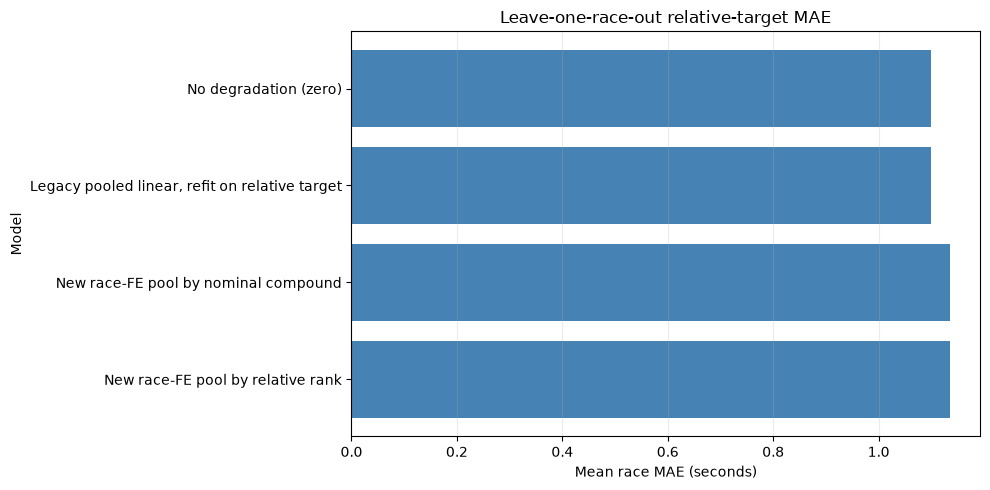

Negative eligible race slopes: 64.9%
SOFT > MEDIUM > HARD in complete new race fits: 31.5% (54 complete races)


,train_years,test_year,model,mae_seconds,laps
0,2022-2023,2024,No degradation (zero),0.886686,21727
1,2022-2023,2024,"Legacy pooled linear, refit on relative target",0.921867,21727
2,2022-2023,2024,New race-FE pool by nominal compound,0.998031,21727
3,2022-2023,2024,New race-FE pool by relative rank,0.998031,21727


In [6]:
race_summary = results["race_summary"].sort_values("mean_race_mae_seconds")
display(race_summary)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(race_summary["model"], race_summary["mean_race_mae_seconds"], color="steelblue")
ax.set(title="Leave-one-race-out relative-target MAE", xlabel="Mean race MAE (seconds)", ylabel="Model")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

negative = results["race_slopes"].loc[~results["race_slopes"]["status"].eq("too_little_data_or_unusable_se"), "slope_seconds_per_lap"].lt(0).mean()
complete = results["race_slopes"].pivot_table(index="race_id", columns="compound", values="slope_seconds_per_lap", aggfunc="first").dropna(subset=["SOFT", "MEDIUM", "HARD"])
ordered = ((complete["SOFT"] > complete["MEDIUM"]) & (complete["MEDIUM"] > complete["HARD"])).mean()
print(f"Negative eligible race slopes: {negative:.1%}")
print(f"SOFT > MEDIUM > HARD in complete new race fits: {ordered:.1%} ({len(complete)} complete races)")
display(results["season_summary"])

## Limitations

The zero-degradation baseline wins this evaluation; the new model is not validated. About 64.9% of eligible new race-level slopes are negative, and 66 of 66 fitted race designs are rank deficient, so the slope estimates and intervals require caution. The nominal pools are negative with intervals that do not support a positive wear effect. Relative rank and SOFT/MEDIUM/HARD are the same ordering in the available data; those labels do not identify the selected Pirelli C1-C5 rubber. Drivers also tend to pit before tyres fall off, creating survivorship bias. Treat the results as exploratory, not causal or strategy guidance.